In [1]:
import logging
logging.basicConfig(level=logging.INFO, force=True)


from networkx.drawing import (
    draw as nx_draw,
    spring_layout,
    kamada_kawai_layout ,
)

from mupt.trees.subselect import NodePredicate
from mupt.mupr.primitives import (
    Primitive,
    RootPrimitive,
    CompositePrimitive,
)
from mupt.mupr.properties import is_atom, is_superatomic, is_subdominant

from mupt.interfaces.smiles import primitive_from_smiles
from mupt.interfaces.mosdef.mbuild import primitive_to_mbuild

INFO:rdkit:Enabling RDKit 2026.09.1 jupyter extensions
INFO:freud.msd:Using SciPy's fftpack for FFTs


# Linear PE homopolymer

In [2]:
num_mols : int = 2
DOP : int = 10

## Assemble MuPT repr

In [3]:
lexicon = {
    'head' : primitive_from_smiles('[H:1]-[C:1](-[H])(-[H])-[C:2](-[H])(-[H])-[*:2]', label="_A"),
    'mid'  : primitive_from_smiles('[*:1]-[C:1](-[H])(-[H])-[C:2](-[H])(-[H])-[*:2]', label="_B"),
    'tail' : primitive_from_smiles('[*:1]-[C:1](-[H])(-[H])-[C:2](-[H])(-[H])-[H:2]', label="_C"),
}

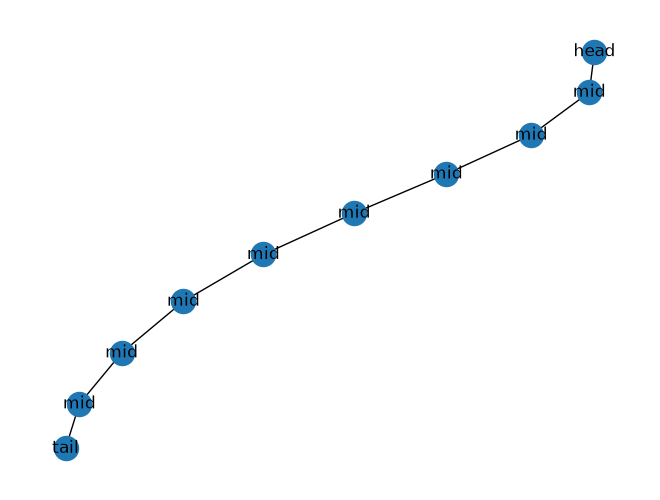

In [4]:
from networkx import get_node_attributes, connected_components
from mupt.graphs.generators import path_graph_from_sequence


label_attr : str = 'label'
sequence_graph = path_graph_from_sequence(
    ['head'] + (DOP - 2)*['mid'] + ['tail'],
    label_attr=label_attr,
)

nx_draw(
    sequence_graph,
    with_labels=True,
    labels=get_node_attributes(sequence_graph, label_attr),
)

### Select, connect, then inspect

In [5]:
# predicate : NodePredicate[Primitive] = lambda prim : is_atom(prim) and prim.element.symbol != 'H'
# predicate : NodePredicate[Primitive] = lambda prim: isinstance(prim.parent, CompositePrimitive)
# predicate : NodePredicate[Primitive] = is_superatomic
predicate : NodePredicate[Primitive] = is_atom

In [6]:
molprim_prototype = CompositePrimitive()
molprim_prototype.populate_from_topology_and_lexicon(
    sequence_graph,
    lexicon,
    label_attr=label_attr,
)

system = RootPrimitive(label='system')
for i in range(num_mols):
    molprim = molprim_prototype.copy()
    molprim.label = f'molecule'
    system.attach_child(molprim)

INFO:mupt.mupr.connection.linking:Paired up 9 new edges after 1 iteration(s); 0/9 edges remain unpaired
INFO:mupt.mupr.connection.linking:Linking protocol successful! 9/9 edges were assigned Connector pairings


In [7]:
xsec = system.cross_section(predicate)
print(f'{len(list(connected_components(xsec)))} molecules')

2 molecules


<Axes: >

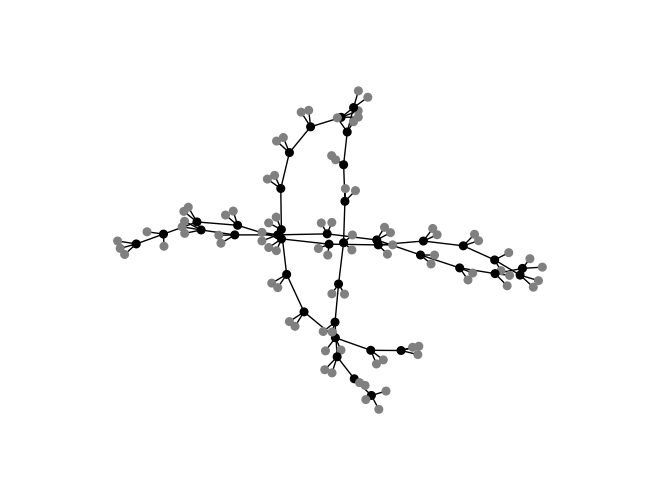

In [8]:
pos = spring_layout(xsec, dim=2)
system.visualize_cross_section(xsec, pos=pos, with_labels=False, node_size=30)

## Export to mbuild

In [9]:
compound = primitive_to_mbuild(
    system,
    predicate=predicate,
    # set False (default) to have Particles directly on Compound
    preserve_intermediates=True, 
)
... # insert downstream code here
print(compound)

<system 124 particles, 122 bonds, non-periodic, id: 6273972752>


In [10]:
# inspect direct descendants of "root" Compound which is returned
display(set(subcomp.name for subcomp in compound.children))

{'molecule'}

from mupt.chemistry.rdkit.depiction import set_rdkdraw_size, hide_atom_indices

set_rdkdraw_size(500, 3/2)
hide_atom_indices()

mols = compound.to_rdkit()
for atom in mols.GetAtoms():
    atom.ClearProp('atomLabel')
display(mols)

In [11]:
print(molprim.hierarchy_summary())

molecule
├── _A
│   ├── H-0
│   ├── C-1
│   ├── H-2
│   ├── H-3
│   ├── C-4
│   ├── H-5
│   ╰── H-6
├── _B
│   ├── C-1
│   ├── H-2
│   ├── H-3
│   ├── C-4
│   ├── H-5
│   ╰── H-6
├── _B
│   ├── C-1
│   ├── H-2
│   ├── H-3
│   ├── C-4
│   ├── H-5
│   ╰── H-6
├── _B
│   ├── C-1
│   ├── H-2
│   ├── H-3
│   ├── C-4
│   ├── H-5
│   ╰── H-6
├── _B
│   ├── C-1
│   ├── H-2
│   ├── H-3
│   ├── C-4
│   ├── H-5
│   ╰── H-6
├── _B
│   ├── C-1
│   ├── H-2
│   ├── H-3
│   ├── C-4
│   ├── H-5
│   ╰── H-6
├── _B
│   ├── C-1
│   ├── H-2
│   ├── H-3
│   ├── C-4
│   ├── H-5
│   ╰── H-6
├── _B
│   ├── C-1
│   ├── H-2
│   ├── H-3
│   ├── C-4
│   ├── H-5
│   ╰── H-6
├── _B
│   ├── C-1
│   ├── H-2
│   ├── H-3
│   ├── C-4
│   ├── H-5
│   ╰── H-6
╰── _C
    ├── C-1
    ├── H-2
    ├── H-3
    ├── C-4
    ├── H-5
    ├── H-6
    ╰── H-7


In [12]:
import warnings

import numpy as np
import unyt as u
from flowermd.base import Molecule

from flowermd.library import (
    UFF_DPD,
    AtomisticRandomWalk,
    LocalBoltzmannSampler,
    PhantomWalk,
)

warnings.filterwarnings("ignore")

chains = Molecule(
    num_mols=1, compound=compound, name="PE", identify_connections=True
)
system = AtomisticRandomWalk(
    chains,
    density=0.78 * u.g / u.cm**3,
    torsion_sampler=LocalBoltzmannSampler(temperature=413),
    seed=1,
)
print("atoms:", system.n_particles, " box (nm):", system.box.Lx)

ff = UFF_DPD(system, file_path="pe_dpd.xml")
system.apply_forcefield(r_cut=0.35, force_field=ff, kT=4.184)
print("types:", system.hoomd_snapshot.particles.types)


sim = PhantomWalk(
    system.hoomd_snapshot,
    system.hoomd_forcefield,
    n_steps_dpd=40000,
    n_steps_fire=100,
    dt=2e-4,
    gsd_write_freq=1e5,
    log_write_freq=1e5,
    run_now=False,
)
record = sim.run_initialization(record_file="pe_record.json")
print("DPD steps:", record["dpd_steps"], " converged:", record["dpd_converged"])
print("ring piercings:", record["ring_piercings"])
print(np.array(record["dpd_energy_history"])[-3:].round(3))

INFO:numexpr.utils:NumExpr defaulting to 11 threads.


OpenMMException: Particle coordinate is NaN.  For more information, see https://github.com/openmm/openmm/wiki/Frequently-Asked-Questions#nan

In [13]:
chains.compound.xyz

array([[0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0

## Update positions of GMSO system from PhantomWalk simulation. Export to file through GMSO

In [ ]:
snap = sim.state.get_snapshot()
system.update_positions(snap)
system.system.save("pe_melt.mol2", overwrite=True)

In [ ]:
from gmso.formats.gro import write_gro
write_gro(system.gmso_system, filename="aa-PAAm.gro")

In [ ]:
#remove hoomd dpd forces
system.remove_typing()

from gmso.formats.lammpsdata import write_lammpsdata
write_lammpsdata(system.gmso_system, filename="aa-PAAm.lammps", atom_style="full")